# 单元07：第一个可运行的线性回归实验

状态：环境准备；当前只做步骤1，学生先写代码，再按真实输出检查。

先使用课程 Population → Profit 数据，再使用 **synthetic data**：ZrB2含量（wt.%）、时效温度（°C）→7085Al复合材料UTS（MPa）。材料模拟数据不能宣称符合真实材料规律，也不能作为实验结果。


## 如何打开

双击同目录 `START_UNIT07.cmd`，或在项目根目录PowerShell运行：

```powershell
.\learning\exercises\START_UNIT07.cmd
```

启动器将IPython及Jupyter配置目录设在项目.venv内，避免默认用户目录权限错误。选择内核 `Unit 07 (.venv)`。GitHub只能预览，执行使用本地JupyterLab。环境详情见 [环境核验记录](unit07-environment.md)。


## 当前步骤1：自己导入四个库

请自己编写代码：导入NumPy（别名np）、pandas（别名pd）、matplotlib.pyplot（别名plt）、sklearn；并打印NumPy、pandas、matplotlib和sklearn的版本。

输入：已安装的软件包，没有样本数据。输出：四个版本号，或实际报错。

shape指数组各个轴的长度；本步没有创建数组，版本号是字符串，不涉及shape。

提示：导入语法为 `import 库名 as 别名`，版本查询通常使用 `库名.__version__`。matplotlib.pyplot是绘图子模块，查询matplotlib版本可额外导入matplotlib。

只运行下面这个单元，把代码及原样输出交给教师检查。首次错误保留，修正版另建单元，不覆盖原始尝试。


In [1]:
import numpy as np
np.__version__
print(np.__version__)
import pandas as pd
pd.__version__
print(pd.__version__)
import matplotlib
print(matplotlib.__version__)
import sklearn as sk
print(sk.__version__)

2.2.6
2.3.3
3.10.7
1.7.2


In [2]:
data = pd.read_csv("data/unit07-ex1data1.txt",header = None)
data.head()
data.shape
X = data[[0]]
X.shape
y = data[[1]]
y.shape
y.head()

,1
0,17.5920
1,9.1302
2,13.6620
3,11.8540
4,6.8233


In [3]:
from sklearn.model_selection import train_test_split
X_train,X_temp,y_train,y_temp = train_test_split(X,y,test_size = 0.4,random_state = 42)#数据划分
print(X_train.shape,X_temp.shape,y_train.shape,y_temp.shape)
X_val,X_test,y_val,y_test = train_test_split(X_temp,y_temp,test_size = 0.5,random_state = 42)
print(X_val.shape,X_test.shape,y_val.shape,y_test.shape)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler() #创建一个标准化器，命名为scaler,变量名 = 工具名称(),变量名scaler 、工具名standardScaler
scaler.fit(X_train) #让scaler从训练集计算均值和标准差
X_train_scaled = scaler.transform(X_train) #转换训练集，并保存结果
print(X_train_scaled.shape)
X_val_scaled = scaler.transform(X_val)# 转换验证集
print(X_val_scaled.shape)
X_test_scaled = scaler.transform(X_test)# 转换测试集
print(X_test_scaled.shape)

from sklearn.linear_model import LinearRegression #导入线性回归模型
model = LinearRegression()#创建一个未训练的回归模型
model.fit(X_train_scaled,y_train)#训练线性回归模型：对象.方法(输入特征, 目标值)；scaler.fit：计算输入特征的均值、标准差。model.fit：根据输入和目标，学习回归直线的斜率、截距。
y_train_pred = model.predict(X_train_scaled)#预测训练集目标值
print(y_train_pred.shape)
y_val_pred = model.predict(X_val_scaled)#预测验证集
print(y_val_pred.shape)
y_test_pred = model.predict(X_test_scaled)#预测测试集
print(y_test_pred.shape)

from sklearn.metrics import mean_absolute_error#导入计算MAE的函数
mae_train = mean_absolute_error(y_train,y_train_pred)#计算训练集MAE:结果变量 = 函数名称(真实值, 预测值)
print(mae_train)
mae_val = mean_absolute_error(y_val,y_val_pred)#计算验证集MAE
print(mae_val)
mae_test = mean_absolute_error(y_test,y_test_pred)#计算测试集MAE
print(mae_test)

from sklearn.metrics import root_mean_squared_error#导入计算RMSE均方根误差的函数
rmse_train = root_mean_squared_error(y_train,y_train_pred)#计算训练集RMSE
print(rmse_train)
rmse_val = root_mean_squared_error(y_val,y_val_pred)#计算验证集RMSE
print(rmse_val)
rmse_test = root_mean_squared_error(y_test,y_test_pred)#计算测试集RMSE
print(rmse_test)

from sklearn.metrics import r2_score#导入计算R2的函数,R² = 1 − 模型平方误差总和 ÷ 均值基准的平方误差总和
r2_train = r2_score(y_train,y_train_pred)#计算训练集R²
print(r2_train)
r2_val = r2_score(y_val,y_val_pred)#计算验证集R²
print(r2_val)
r2_test = r2_score(y_test,y_test_pred)#计算测试集R²
print(r2_test)

(58, 1) (39, 1) (58, 1) (39, 1)
(19, 1) (20, 1) (19, 1) (20, 1)
(58, 1)
(19, 1)
(20, 1)
(58, 1)
(19, 1)
(20, 1)
2.1256079577614337
2.013605107112253
2.495643609921872
2.8113496156250872
2.51613784515522
3.8611253088773583
0.7192677346434027
0.6008689506565247
0.6555893767196204


Text(0, 0.5, 'Predicted target')

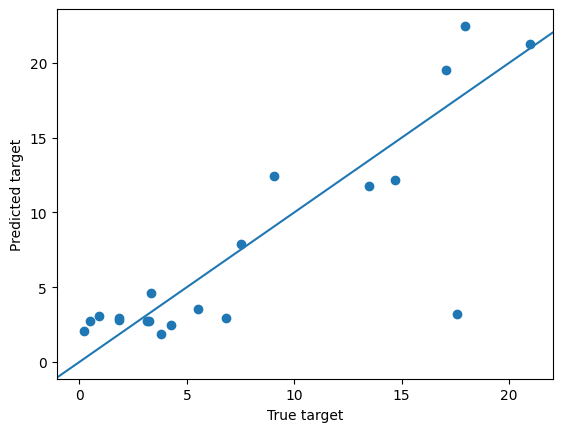

In [4]:
import matplotlib.pyplot as plt
plt.scatter(y_test,y_test_pred)#散点函数
plt.axline((0,0),slope=1)#添加参考线
plt.xlabel("True target")#添加标签，设置横轴文字
plt.ylabel("Predicted target")

(100, 3)
(100, 2)
(100, 1)
(60, 2) (40, 2) (60, 1) (40, 1)
(20, 2) (20, 2) (20, 1) (20, 1)
(60, 2)
(20, 2)
(20, 2)
(60, 1)
(20, 1)
(20, 1)
5.394357843156145
4.612474976810458
5.927584783266172
6.730123053576296
5.452441594376121
7.214085276099755
0.8120619482888763
0.7860321601276603
0.7264239400097976


Text(0, 0.5, 'Predicted UTS/MPa')

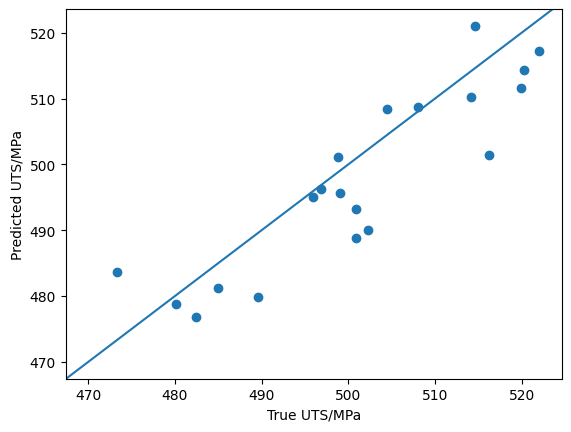

In [5]:
materials_data = pd.read_csv("data/unit07-materials-synthetic.csv")
materials_data.head()
print(materials_data.shape)
X_materials = materials_data[["ZrB2_wt_pct","aging_temperature_C"]]
print(X_materials.shape)
y_materials = materials_data[["UTS_MPa"]]
print(y_materials.shape)

X_materials_train,X_materials_temp,y_materials_train,y_materials_temp = train_test_split(X_materials,y_materials,train_size = 0.6,random_state = 42)
print(X_materials_train.shape,X_materials_temp.shape,y_materials_train.shape,y_materials_temp.shape)
X_materials_val,X_materials_test,y_materials_val,y_materials_test = train_test_split(X_materials_temp,y_materials_temp,test_size = 0.5,random_state = 42)
print(X_materials_val.shape,X_materials_test.shape,y_materials_val.shape,y_materials_test.shape)
scaler_materials = StandardScaler()
scaler_materials.fit(X_materials_train)
X_materials_train_scaled = scaler_materials.transform(X_materials_train)
print(X_materials_train_scaled.shape)
X_materials_val_scaled = scaler_materials.transform(X_materials_val)
print(X_materials_val_scaled.shape)
X_materials_test_scaled = scaler_materials.transform(X_materials_test)
print(X_materials_test_scaled.shape)

model_materials = LinearRegression()
model_materials.fit(X_materials_train_scaled,y_materials_train)
y_materials_train_pred = model_materials.predict(X_materials_train_scaled)
print(y_materials_train_pred.shape)
y_materials_val_pred = model_materials.predict(X_materials_val_scaled)
print(y_materials_val_pred.shape)
y_materials_test_pred = model_materials.predict(X_materials_test_scaled)
print(y_materials_test_pred.shape)

mae_materials_train = mean_absolute_error(y_materials_train,y_materials_train_pred)
print(mae_materials_train)
mae_materials_val = mean_absolute_error(y_materials_val,y_materials_val_pred)
print(mae_materials_val)
mae_materials_test = mean_absolute_error(y_materials_test,y_materials_test_pred)
print(mae_materials_test)

rmse_materials_train = root_mean_squared_error(y_materials_train,y_materials_train_pred)
print(rmse_materials_train)
rmse_materials_val = root_mean_squared_error(y_materials_val,y_materials_val_pred)
print(rmse_materials_val)
rmse_materials_test = root_mean_squared_error(y_materials_test,y_materials_test_pred)
print(rmse_materials_test)

r2_materials_train = r2_score(y_materials_train,y_materials_train_pred)
print(r2_materials_train)
r2_materials_val = r2_score(y_materials_val,y_materials_val_pred)
print(r2_materials_val)
r2_materials_test = r2_score(y_materials_test,y_materials_test_pred)
print(r2_materials_test)

plt.scatter(y_materials_test,y_materials_test_pred)#散点函数
plt.axline((470,470),slope=1)#添加参考线
plt.xlabel("True UTS/MPa")#添加标签，设置横轴文字
plt.ylabel("Predicted UTS/MPa")

In [6]:
#选择数据
materials_data = pd.read_csv("data/unit07-materials-synthetic.csv")
X_materials_check = materials_data[["ZrB2_wt_pct","aging_temperature_C"]]
y_materials_check = materials_data[["UTS_MPa"]]

#划分数据
X_materials_check_train,X_materials_check_temp,y_materials_check_train,y_materials_check_temp = train_test_split(X_materials_check,y_materials_check,test_size = 0.4,random_state = 7)
X_materials_check_val,X_materials_check_test,y_materials_check_val,y_materials_check_test = train_test_split(X_materials_check_temp,y_materials_check_temp,test_size = 0.5,random_state = 7)

#标准化
scaler_materials_check = StandardScaler()
scaler_materials_check.fit(X_materials_check_train)
X_materials_check_train_scaled = scaler_materials_check.transform(X_materials_check_train)
X_materials_check_val_scaled = scaler_materials_check.transform(X_materials_check_val)
X_materials_check_test_scaled = scaler_materials_check.transform(X_materials_check_test)

#训练线性回归模型
model_materials_check = LinearRegression()
model_materials_check.fit(X_materials_check_train_scaled,y_materials_check_train)
y_materials_check_train_pred = model_materials_check.predict(X_materials_check_train_scaled)
y_materials_check_val_pred = model_materials_check.predict(X_materials_check_val_scaled)
y_materials_check_test_pred = model_materials_check.predict(X_materials_check_test_scaled)

#测试集MAE
mae_materials_check_test = mean_absolute_error(y_materials_check_test,y_materials_check_test_pred)
print(mae_materials_check_test)

#预测新批次X_new_check
X_new_check = pd.DataFrame(
    [[0.50, 140.0], [1.50, 170.0]],
    columns=["ZrB2_wt_pct", "aging_temperature_C"]
)
X_new_check_scaled = scaler_materials_check.transform(X_new_check)#转换
y_new_check_pred = model_materials_check.predict(X_new_check_scaled)#预测
print(y_new_check_pred)
print(y_new_check_pred.shape)

5.358826057468858
[[493.83202391]
 [503.35781219]]
(2, 1)


## 学生解释与真实运行记录

尚未收到学生代码或运行结果。

记录顺序：首次代码 → 原样输出/traceback（报错详情）→ 学生解释 → 教师提示 → 修正代码 → 重新运行结果。区分学生运行和教师核验，不预填成绩。


## 后续步骤（逐步开放，不预填答案）

课程数据 → 构造X/y → shape → 三份划分 → 训练特征fit StandardScaler → 三组transform → LinearRegression训练 → 三组预测 → MAE/RMSE/R² → 目标/预测散点图 → 解释局限 → synthetic材料教学数据重复独立流程。

X表示特征矩阵，shape为(m,n)；y表示目标列数组，shape为(m,1)；y_hat表示预测值，也检查为(m,1)。m为样本数，n为特征数。保持此前二维目标列约定；使用sklearn默认截距，不额外加常数列。目标保留原单位。

本单元不引入交叉验证、复杂调参或新模型。先划分，再仅用训练特征拟合缩放器；验证/测试复用训练规则。设置在查看最终测试结果前固定，不反复据测试表现修改方案。

课程数据副本：`data/unit07-ex1data1.txt`（相对Notebook目录），出处见 [数据来源](data/unit07-data-source.md)。原课程Notebook已只读审阅，未执行。synthetic材料数据尚未生成，之后明确生成假设与随机种子；无炉次变量时的逐行教学划分不证明全新炉次性能，若引入炉次则先确定预测目标和整组边界。
